In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-rating-prediction")

print("Path to dataset files:", path)

/Users/martyna/dev/iron hack/Week 1/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 117M/117M [00:04<00:00, 24.8MB/s] 

Extracting files...


Path to dataset files: /Users/martyna/.cache/kagglehub/datasets/asaniczka/uk-optimal-product-price-prediction/versions/3


In [34]:
import matplotlib.pyplot as plt

In [12]:
import pandas as pd
df = pd.read_csv('/Users/martyna/.cache/kagglehub/datasets/asaniczka/uk-optimal-product-price-prediction/versions/3/amz_uk_price_prediction_dataset.csv')

In [13]:
df_copy = df.copy()

In [39]:
df_copy.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


### Part 1

In [ ]:
#frequency table
df_category = df_copy.groupby("category")["uid"].count().reset_index().sort_values(by="uid",ascending=False)

In [28]:
df_category

,category,uid
262,Sports & Outdoors,836265
20,Beauty,19312
116,"Handmade Clothing, Shoes & Accessories",19229
16,Bath & Body,19092
29,Birthday Gifts,18978
...,...,...
195,Motorbike Chassis,107
226,Plugs,107
6,Alexa Built-In Devices,107
254,Smart Home Security & Lighting,104


In [30]:
#top 5 categories
top_categories = df_category["category"].head(5).tolist()

In [31]:
print(f"Top 5 listed categorie are {top_categories}")

Top 5 listed categorie are ['Sports & Outdoors', 'Beauty', 'Handmade Clothing, Shoes & Accessories', 'Bath & Body', 'Birthday Gifts']


In [37]:
df_top10 = df_category.head(10)

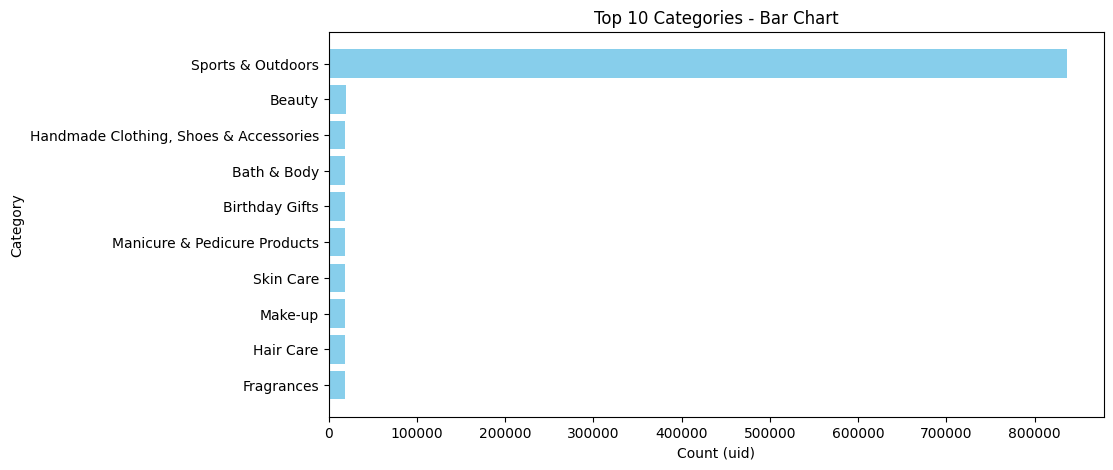

In [35]:
#bar chart
plt.figure(figsize=(10, 5))
plt.barh(df_top10["category"], df_top10["uid"], color='skyblue')
plt.xlabel("Count (uid)")
plt.ylabel("Category")
plt.title("Top 10 Categories - Bar Chart")
plt.gca().invert_yaxis()  # Invert y-axis for better readability
plt.show()

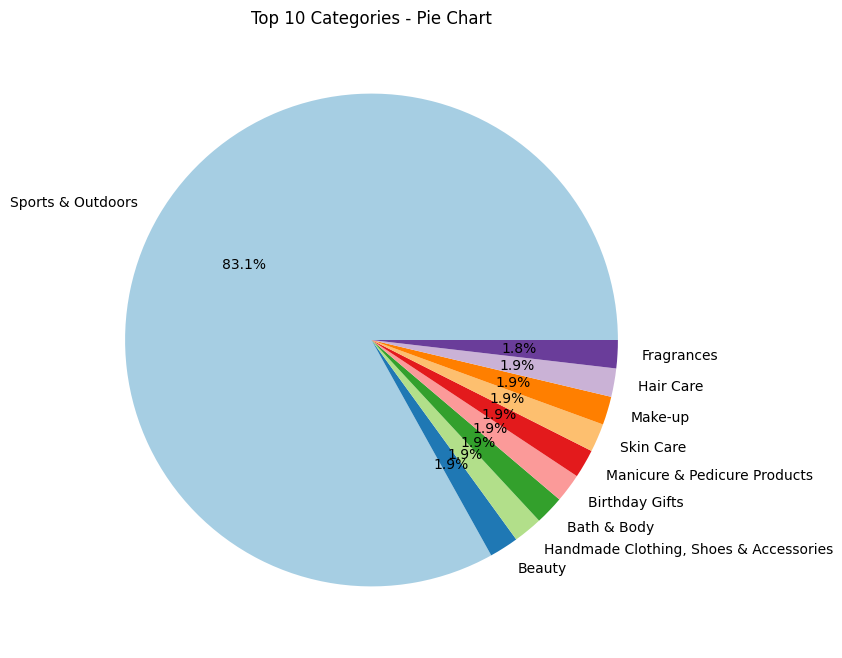

In [38]:
#pie chart
plt.figure(figsize=(8, 8))
plt.pie(df_top10["uid"], labels=df_top10["category"], autopct="%1.1f%%", colors=plt.cm.Paired.colors)
plt.title("Top 10 Categories - Pie Chart")
plt.show()


83.1% of all listings come from 'SPorts & Outdoors' category

### Part 2

In [54]:
price_mean = round(float(df_copy["price"].mean()),2)

In [55]:
price_median = round(float(df_copy["price"].median()),2)

In [57]:
price_mode = round(float(df_copy["price"].mode()),2)

/var/folders/8m/yz8tmn5d3ns2cwtr98zklxtw0000gn/T/ipykernel_71316/506729522.py:1: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  price_mode = round(float(df_copy["price"].mode()),2)


In [58]:
price_diff = price_mean - price_mode

In [60]:
print(f"Mean price is {price_mean} and is {price_diff} higher than mode")

Mean price is 89.24 and is 79.25 higher than mode


In [61]:
df_copy["price"].describe()

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

In [62]:
variance = df_copy["price"].var()
print("Variance:", variance)

Variance: 119445.48532254907


In [65]:
std_dev = round(df_copy["price"].std(),2)
print("Standard Deviation:", std_dev)

Standard Deviation: 345.61


In [66]:
print(f"On average, the price deviates {std_dev} euros from the mean ({price_mean})")

On average, the price deviates 345.61 euros from the mean (89.24)


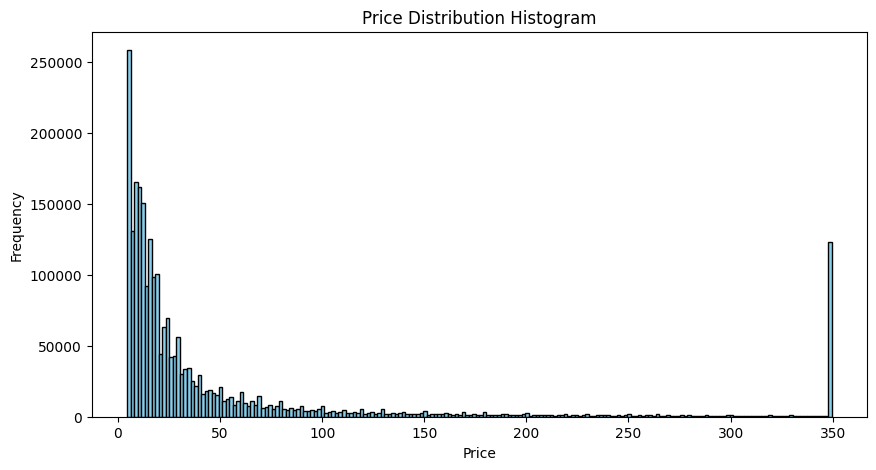

In [77]:
#histogram with prices
lower, upper = df["price"].quantile(0.05), df["price"].quantile(0.95)  # Clipping at 5th and 95th percentile

# Apply clipping to remove extreme outliers
price_clipped = df["price"].clip(lower=lower, upper=upper)


plt.figure(figsize=(10, 5))
plt.hist(price_clipped, bins=200, color='skyblue', edgecolor='black')
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.title("Price Distribution Histogram")
plt.show()

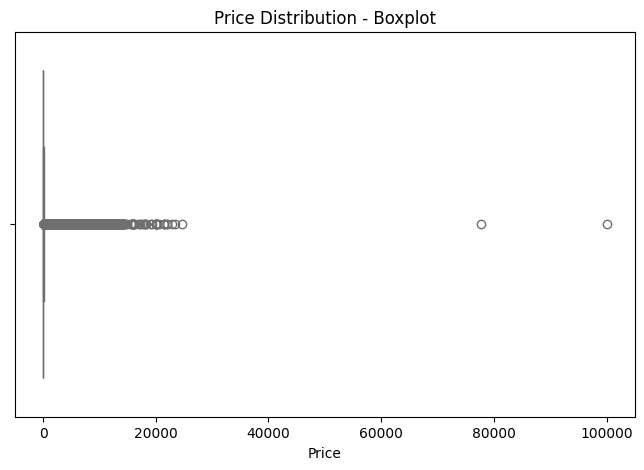

In [78]:
import seaborn as sns
# Create boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["price"], color="skyblue")
plt.xlabel("Price")
plt.title("Price Distribution - Boxplot")
plt.show()

We can see significant outliers in the data. Vast majority of products is prices below 50 euros, but we also see many products prices at more than 1000 euros

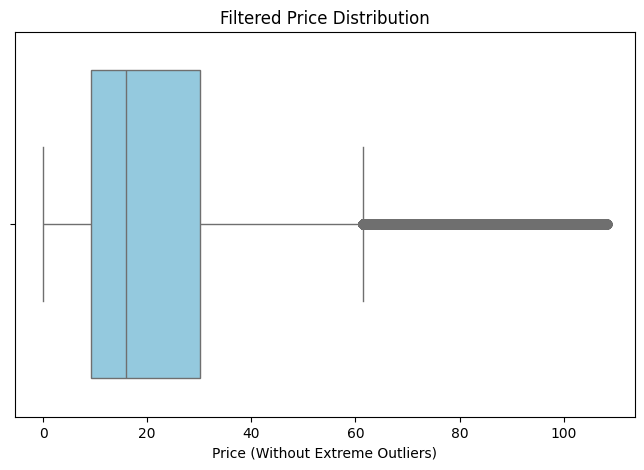

In [80]:
#removing outliers for cleaner view
Q1 = df_copy["price"].quantile(0.05)
Q3 = df_copy["price"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_filtered = df_copy[(df_copy["price"] >= lower_bound) & (df_copy["price"] <= upper_bound)]

plt.figure(figsize=(8, 5))
sns.boxplot(x=df_filtered["price"], color="skyblue")
plt.xlabel("Price (Without Extreme Outliers)")
plt.title("Filtered Price Distribution")
plt.show()

Looking at values between 5th quantile and 75th quantile we can see that IQR limits are between 10 and 30, and outliers start > 60

### Part 3

In [83]:
rating_mean = round(float(df_copy["stars"].mean()),2)

In [84]:
rating_median = round(float(df_copy["stars"].median()),2)

In [85]:
rating_mode = round(float(df_copy["stars"].mode()),2)

/var/folders/8m/yz8tmn5d3ns2cwtr98zklxtw0000gn/T/ipykernel_71316/4014042866.py:1: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  rating_mode = round(float(df_copy["stars"].mode()),2)


In [86]:
print(f"Ratings have following central values: mean is {rating_mean}, median is {rating_median}, mode is {rating_mode}")

Ratings have following central values: mean is 2.15, median is 0.0, mode is 0.0


In [98]:
df_stars = df_copy.groupby("stars")["uid"].count().reset_index()

In [99]:
df_stars["percent"] = (df_stars["uid"] / df_stars["uid"].sum()) * 100  # Calculate percentage
df_stars = df_stars.sort_values(by="percent", ascending=False).head(10)  # Sort descending

In [100]:
df_stars.reset_index(inplace=True,drop=True)

In [101]:
df_stars

,stars,uid,percent
0,0.0,1225641,50.156139
1,4.5,151577,6.202891
2,4.6,136995,5.606161
3,4.4,136165,5.572195
4,5.0,128492,5.258198
5,4.3,112564,4.606386
6,4.7,94566,3.869865
7,4.2,86871,3.554968
8,4.0,66089,2.704519
9,4.1,65115,2.664660


50% of the products don't have a rating, for future analysis I will only consider products which did get a rating 

In [104]:
df_rated = df_copy[df_copy["stars"] != 0]

In [105]:
df_rated

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443642,2828585,B07DCFQMQL,Speed MaxX BODY ARMOUR CE MOTORBIKE/MOTORCYCLE...,3.6,66,49.99,False,0,Motorbike Clothing
2443643,2828586,B07JM5VQFX,Motorcycle Clothing Suit - Motorbike Suit With...,4.1,5,158.99,False,0,Motorbike Clothing
2443644,2828587,B07X98JLFF,GREAT BIKERS GEAR - Bobber Cafe Brat Style Lea...,3.6,12,14.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [107]:
import numpy as np

# Calculate variance
rating_variance = df_rated["stars"].var()

# Calculate standard deviation
rating_std_dev = df_rated["stars"].std()

# Calculate interquartile range (IQR)
Q1 = df_rated["stars"].quantile(0.25)
Q3 = df_rated["stars"].quantile(0.75)
rating_IQR = Q3 - Q1

# Print results
print(f"Variance: {rating_variance}")
print(f"Standard Deviation: {rating_std_dev}")
print(f"Interquartile Range (IQR): {rating_IQR}")

Variance: 0.30834337523872835
Standard Deviation: 0.5552867504620729
Interquartile Range (IQR): 0.5


There is a wide spread in the ranking. For the analysis here I excluded product without rating. For the rated products we see a IQR value of 0.5, which means that middle 50% of ratings are spred by 0.5 stars. 

In [111]:
from scipy.stats import skew, kurtosis

In [113]:
# Calculate skewness
rating_skewness = skew(df_rated["stars"])

# Calculate kurtosis
rating_kurtosis = kurtosis(df_rated["stars"])

# Print results
print(f"Skewness: {rating_skewness}")
print(f"Kurtosis: {rating_kurtosis}")

Skewness: -2.3795651817332506
Kurtosis: 9.781892609238655


From the results we can say that tail is longer on the left (more low reviews, skewness < 0) and that there are heavy tails (kurtosis > 3)

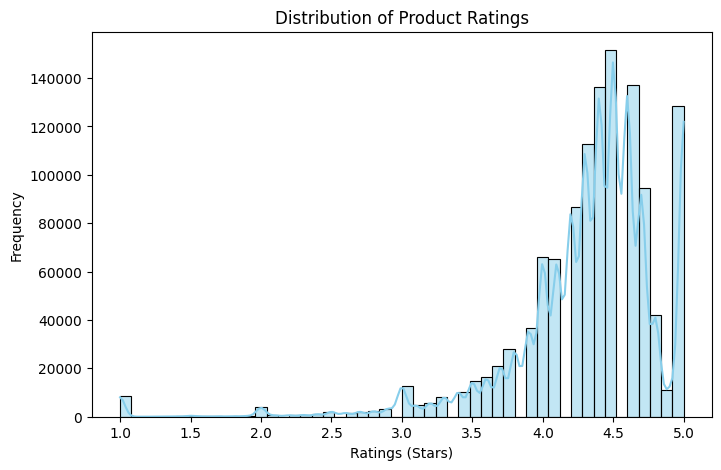

In [117]:
#only rated products
plt.figure(figsize=(8, 5))
sns.histplot(df_rated["stars"], bins=50, kde=True, color="skyblue")
plt.xlabel("Ratings (Stars)")
plt.ylabel("Frequency")
plt.title("Distribution of Product Ratings")
plt.show()

We can see that the most common is 4.5 rating

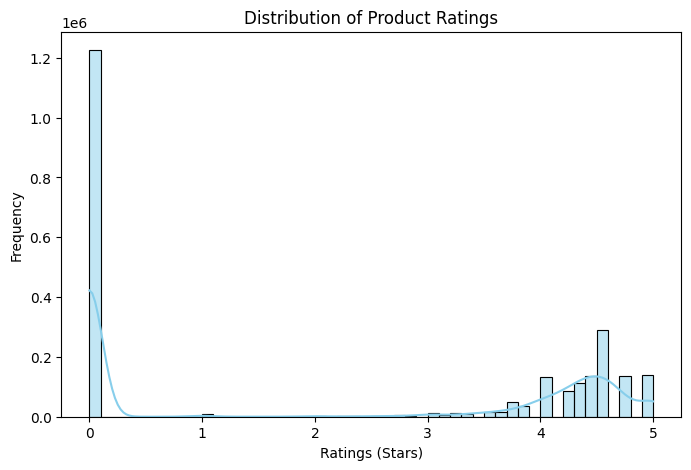

In [118]:
#all products
plt.figure(figsize=(8, 5))
sns.histplot(df_copy["stars"], bins=50, kde=True, color="skyblue")
plt.xlabel("Ratings (Stars)")
plt.ylabel("Frequency")
plt.title("Distribution of Product Ratings")
plt.show()

When looking at all producst, we see again that most of them don't have any rating at all.